# Call center staffing: forecast again at ten o'clock

**Averaging the last four same weekdays, a forecast of tomorrow's calls is no better made the evening before than two weeks ahead. The news is elsewhere: how far yesterday ran above its forecast takes 15% off the miss, and the calls taken by 10:00 take another 12% off the rest of the day. Rescaling the forecast to the morning in full, the first thing most people would try, makes it worse until late morning.**

A call center plans in steps. The roster is drawn up weeks ahead. The evening before there is still time to call people in, and during the day breaks, training and overtime can be moved. Each step could use a newer forecast. This notebook measures what each newer forecast is worth on seven months of calls to a bank, and meets a trap in the calendar on the way.

*Data: calls to a North American bank's call center in each half hour of 164 working days in 2003, from the R package fpp3 ([source and license](data/README.md#bank-calls)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from timegym import LastValueForecaster, Pipeline, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## The job

The center is open from 7:00 to 21:00 on working days, which makes 28 half hours a day. The job is to say how many calls each half hour will bring, so that enough agents are on the phones. The table has a row for every half hour the center was open and no rows for the rest.

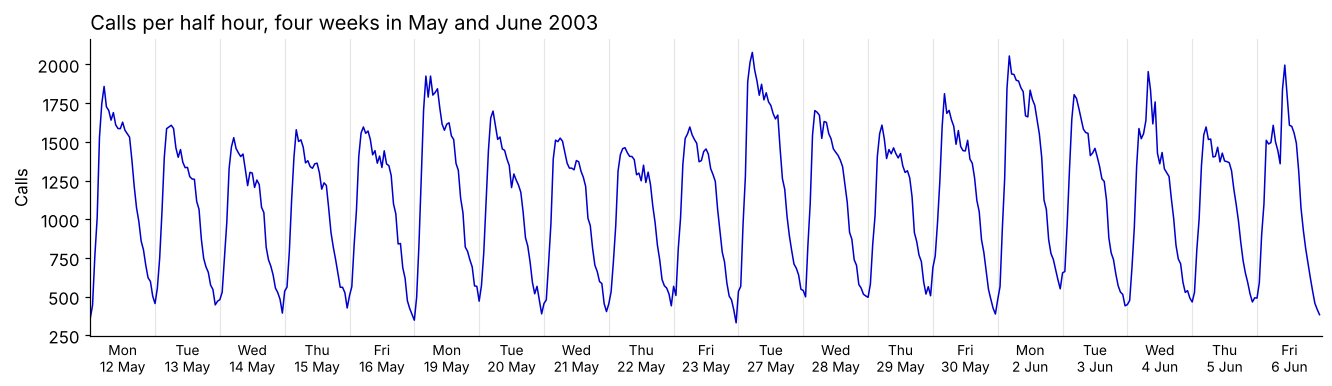

164 working days, 3 March to 24 October 2003, 28 half hours each.
Calls on an average day: 32,392. On an average Monday: 36,339.
Weekdays with no rows: 4 April, 7 April, 26 May, 4 July, 1 September, 14 October.


In [2]:
calls = load("bank-calls")
SLOTS = 28                                    # half hours in a working day, 7:00 to 21:00
days = calls.index.normalize().unique()
assert len(calls) == SLOTS * len(days) and (calls.groupby(calls.index.normalize()).size() == SLOTS).all()


def day_month(day):
    return f"{day.day} {day:%B}"


shown = calls.loc["2003-05-12":"2003-06-06", "calls"]
starts = np.arange(0, len(shown), SLOTS)
fig, ax = plt.subplots(figsize=(12, 3.4), layout="constrained")
ax.plot(np.arange(len(shown)), shown.to_numpy(), color="#0000CC", linewidth=1)
for start in starts[1:]:
    ax.axvline(start, color="0.9", linewidth=0.8, zorder=0)
ax.set_xticks(starts + SLOTS / 2, [f"{day:%a}\n{day.day} {day:%b}" for day in shown.index[starts]], fontsize=9)
ax.tick_params(axis="x", length=0)
ax.set(title="Calls per half hour, four weeks in May and June 2003", ylabel="Calls", xlim=(0, len(shown)))
plt.show()

by_day = calls["calls"].groupby(calls.index.normalize()).sum()
mondays = by_day[by_day.index.day_of_week == 0]
missing = pd.bdate_range(days[0], days[-1]).difference(days)
print(f"{len(days)} working days, {day_month(days[0])} to {day_month(days[-1])} 2003, {SLOTS} half hours each.")
print(f"Calls on an average day: {by_day.mean():,.0f}. On an average Monday: {mondays.mean():,.0f}.")
print(f"Weekdays with no rows: {', '.join(day_month(day) for day in missing)}.")
assert len(days) == 164 and len(missing) == 6 and pd.Timestamp("2003-05-26") in missing

Every day has the same shape: a climb to a peak around 10:00, then a long slope down. Mondays are the busiest day. And the calendar has holes. There are no nights and no weekends, and six weekdays have no rows at all, among them Memorial Day, the Fourth of July and Labor Day. In the picture, Monday 26 May is not there, and the Tuesday that follows looks like a Monday.

## The evening before

Start with the plain version of the job: at closing time, forecast all 28 half hours of the next working day. The first 60 days are kept for the forecasters to learn from and the last 104 are the test, one case per day. For `cases_from_series`, an origin is a number of rows of history and the horizon is a number of rows to forecast. So "the next 28 rows" is the next working day, whatever lies in between.

TimeGym's built-in forecasters are the natural place to start.

In [3]:
FIRST = 60                                    # the first test day; the 60 days before it are for learning


def cases_at(known):
    "One case per test day. Its history ends `known` half hours into the day; the rest of the day is to forecast."
    origins = [SLOTS * day + known for day in range(FIRST, len(days))]
    return cases_from_series(calls, origins=origins, horizon=SLOTS - known, name="bank-calls")


evening = cases_at(0)
run = Pipeline(LastValueForecaster()).run(cases=evening)
print(run.report.summary["status_counts"])
print(run.cases[0].diagnostics[0].message)
assert run.report.summary["status_counts"]["ERROR"] == len(evening) == 104

{'PASS': 0, 'FAIL': 0, 'INCONCLUSIVE': 0, 'UNSUPPORTED': 0, 'ERROR': 104}
ValueError: Step-based models require a regular context index with a known frequency


The run finishes, and all 104 cases are recorded as errors with the reason. The built-in forecasters work in steps, and they will not run where a step has no fixed length. Here the step from 20:30 to 7:00 is one row. So is the step from Friday to Monday, or to Tuesday when Monday is a holiday. TimeGym does not guess what a step means.

A forecaster of your own is handed the history with its dates, and the dates it must forecast, so it can read the calendar. To see what that is worth, here is one idea written twice: *the average of this half hour on the last four days that fell on the same weekday*.

- **Counting rows** finds those days the way a spreadsheet or a `shift` would. A week is 5 days of 28 rows, so last week is 140 rows back.
- **By date** looks up the weekday of every day in the history.

Two simpler forecasters are scored beside them: the same as yesterday, and the same weekday last week (by date).

In [4]:
def slot(times):
    "Position of each time in the working day: 0 for 7:00, 27 for 20:30."
    return np.asarray((times.hour * 60 + times.minute - 7 * 60) // 30)


class Yesterday:
    "Every half hour as on the last working day."

    def fit(self, history):
        self.last_ = history["calls"].to_numpy(float)[-SLOTS:]
        return self

    def predict(self, dates):
        return self.last_[slot(dates)]


class CountingRows:
    "Each half hour's average over the rows 1, 2, 3 and 4 weeks back, a week being 140 rows."

    def fit(self, history):
        calls = history["calls"].to_numpy(float)
        back = 5 * SLOTS * np.arange(1, 5)
        self.usual_ = np.array([calls[len(calls) + half_hour - back].mean() for half_hour in range(SLOTS)])
        return self

    def predict(self, dates):
        return self.usual_[slot(dates)]


class SameWeekdays:
    "Each half hour's average over the last few days that fell on the same weekday, found by date."

    def __init__(self, weeks=4):
        self.weeks = weeks

    def fit(self, history):
        calls = history["calls"]
        whole_days = calls.iloc[: len(calls) - len(calls) % SLOTS]      # leave out a day that is still running
        table = whole_days.to_numpy(float).reshape(-1, SLOTS)
        weekday = whole_days.index[::SLOTS].day_of_week.to_numpy()
        self.usual_ = {day: table[weekday == day][-self.weeks:].mean(axis=0) for day in range(5)}
        return self

    def predict(self, dates):
        return np.array([self.usual_[day][half_hour] for day, half_hour in zip(dates.day_of_week, slot(dates))])


def run_all(model, cases, metrics=None):
    "Run a forecaster on every case and check that none failed."
    run = Pipeline(model).run(cases=cases, metrics=metrics, keep_data=True)
    run.assert_passed()   # stop here if any forecast crashed or failed a check
    return run


def metric(run, name="mae"):
    return run.metrics[name].to_numpy()


forecasters = {
    "Same as yesterday": Yesterday(),
    "Same weekday last week": SameWeekdays(1),
    "Last 4 same weekdays, counting rows": CountingRows(),
    "Last 4 same weekdays, by date": SameWeekdays(4),
}
runs = {name: run_all(model, evening) for name, model in forecasters.items()}
miss = {name: metric(run) for name, run in runs.items()}
typical = float(np.mean([case.observed.to_numpy().mean() for case in evening]))
table = pd.DataFrame({"Average miss": {name: values.mean() for name, values in miss.items()}})
table["% of a half hour"] = 100 * table["Average miss"] / typical
display(table.round(1).rename_axis(f"{len(evening)} test days"))
print(f"The miss is in calls per half hour; an average half hour has {typical:,.0f}.")

rows, best = "Last 4 same weekdays, counting rows", "Last 4 same weekdays, by date"
weekday = days.day_of_week.to_numpy()
lined_up = np.array([all(weekday[day - 5 * week] == weekday[day] for week in range(1, 5))
                     for day in range(FIRST, len(days))])   # 140, 280, 420 and 560 rows back: the same weekday?
split = pd.DataFrame({"Days": [lined_up.sum(), (~lined_up).sum()],
                      "Counting rows": [miss[rows][lined_up].mean(), miss[rows][~lined_up].mean()],
                      "By date": [miss[best][lined_up].mean(), miss[best][~lined_up].mean()]},
                     index=["Rows and weekdays line up", "They do not"])
display(split.round(1))

assert [round(miss[name].mean(), 1) for name in forecasters] == [122.5, 100.9, 93.8, 79.7]
assert lined_up.sum() == 38 and np.allclose(miss[rows][lined_up], miss[best][lined_up])
assert split.round(1).loc["They do not"].tolist() == [66, 105.1, 83.0]

,Average miss,% of a half hour
104 test days,,
Same as yesterday,122.5,10.6
Same weekday last week,100.9,8.7
"Last 4 same weekdays, counting rows",93.8,8.1
"Last 4 same weekdays, by date",79.7,6.9


The miss is in calls per half hour; an average half hour has 1,161.


,Days,Counting rows,By date
Rows and weekdays line up,38,74.1,74.1
They do not,66,105.1,83.0


Counting rows costs 18% (93.8 against 79.7). The second table shows where. On the 38 test days where the rows 140, 280, 420 and 560 back all fall on the same weekday, the two are the same forecaster and miss by the same 74.1 calls. On the other 66 days a missing weekday has shifted the rows, and for four weeks after each one the row counter averages Mondays into Tuesdays. Nothing fails and nothing is printed. The forecast is only worse.

Reading the dates, the average of the last four same weekdays misses a half hour by 79.7 calls, about 7% of what a half hour brings.

## Does it matter when the forecast is made?

A roster is drawn up long before the evening before. To see what the wait is worth, cut the cases ten working days earlier and ask for ten days at once. A metric of our own measures the miss on the tenth day only, which is the same day the evening forecast is scored on.

In [5]:
def tenth_day_miss(observed, predicted):
    "Average miss on the last day of a ten-day forecast."
    return float(np.abs(observed[-SLOTS:] - predicted[-SLOTS:]).mean())


origins = [SLOTS * (day - 9) for day in range(FIRST, len(days))]
two_weeks = cases_from_series(calls, origins=origins, horizon=10 * SLOTS, name="bank-calls")
assert all(early.observed.index[-1] == late.observed.index[-1] for early, late in zip(two_weeks, evening))

ahead = metric(run_all(SameWeekdays(4), two_weeks, metrics={"tenth_day_miss": tenth_day_miss}), "tenth_day_miss")
gap = paired_t_interval(ahead - miss[best])
print(f"Average miss, forecast made ten working days ahead: {ahead.mean():.1f}")
print(f"Average miss, forecast made the evening before:     {miss[best].mean():.1f}")
print(f"Difference: {gap['mean']:+.1f} calls (95% interval {gap['ci95'][0]:+.1f} to {gap['ci95'][1]:+.1f})")
assert round(ahead.mean(), 1) == 78.4 and gap["ci95"][0] < 0 < gap["ci95"][1]

Average miss, forecast made ten working days ahead: 78.4
Average miss, forecast made the evening before:     79.7
Difference: -1.4 calls (95% interval -5.3 to +2.6)


Made two weeks ahead, the forecast misses by 78.4 calls; made the evening before, by 79.7. The interval on the difference runs from below zero to above it, so there is no difference to speak of. An average over four weeks moves too slowly to notice anything recent, and a roster built on it loses nothing by being early. If the last days hold any news, this forecaster is not reading it.

## A day is busy or quiet as a whole

So where does the miss come from? The run kept every forecast and every answer. For each test day, compare the calls that came with the calls that were forecast, as a share: over the whole day, before 10:00, and from 10:00 on. Call that share the day's surprise.

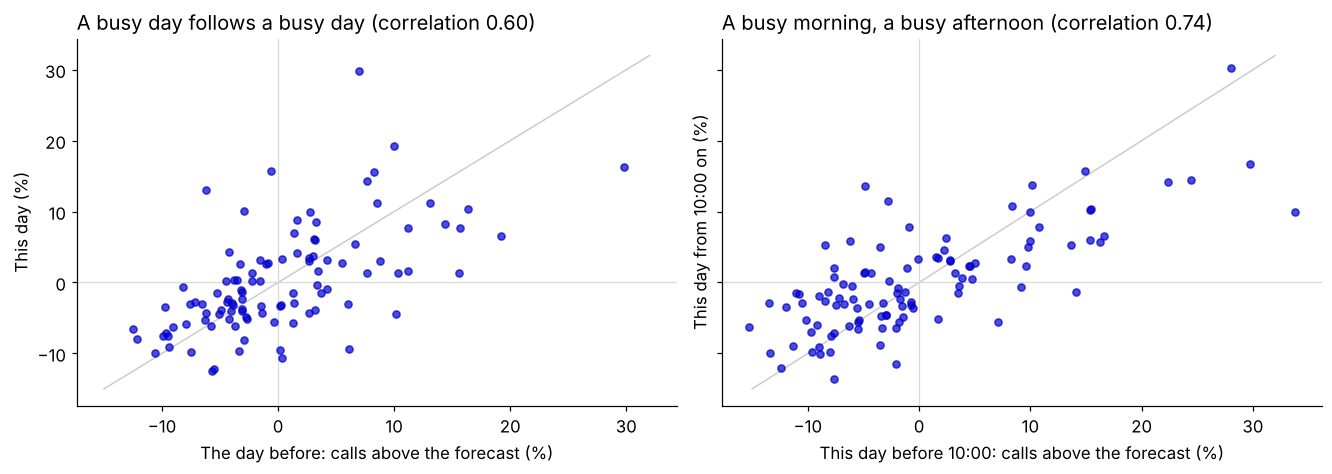

On a typical test day the calls come in 5.7% above or below the forecast.
Furthest above: +29.8% on 2 September.
Furthest below: -12.5% on 9 September.


In [6]:
def above(actual, expected):
    "How far the calls ran above the forecast, as a share: 0.10 is 10% above, -0.05 is 5% below."
    return np.sum(actual, axis=-1) / np.sum(expected, axis=-1) - 1


forecast = np.array([entry.forecast.point[:, 0] for entry in runs[best].cases])      # test days x half hours
came = np.array([entry.observed.to_numpy()[:, 0] for entry in runs[best].cases])
whole, morning, rest = above(came, forecast), above(came[:, :6], forecast[:, :6]), above(came[:, 6:], forecast[:, 6:])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained", sharey=True)
pairs = [(whole[:-1], whole[1:], "The day before", "This day", "A busy day follows a busy day"),
         (morning, rest, "This day before 10:00", "This day from 10:00 on", "A busy morning, a busy afternoon")]
for ax, (x, y, x_label, y_label, title) in zip(axes, pairs):
    ax.plot([-15, 32], [-15, 32], color="0.8", linewidth=1, zorder=0)
    ax.scatter(100 * x, 100 * y, s=22, color="#0000CC", alpha=0.7)
    ax.axhline(0, color="0.85", linewidth=0.8, zorder=0)
    ax.axvline(0, color="0.85", linewidth=0.8, zorder=0)
    ax.set(title=f"{title} (correlation {np.corrcoef(x, y)[0, 1]:.2f})",
           xlabel=f"{x_label}: calls above the forecast (%)", ylabel=f"{y_label} (%)")
plt.show()

test_days = days[FIRST:]
print(f"On a typical test day the calls come in {100 * np.abs(whole).mean():.1f}% above or below the forecast.")
print(f"Furthest above: {100 * whole.max():+.1f}% on {day_month(test_days[whole.argmax()])}.")
print(f"Furthest below: {100 * whole.min():+.1f}% on {day_month(test_days[whole.argmin()])}.")
assert round(np.corrcoef(morning, rest)[0, 1], 2) == 0.74 and round(np.corrcoef(whole[:-1], whole[1:])[0, 1], 2) == 0.60
assert test_days[whole.argmax()] == pd.Timestamp("2003-09-02")
far_above = morning > 0.20                          # mornings more than 20% above the forecast
assert far_above.sum() == 5 and (rest[far_above] < morning[far_above] - 0.05).sum() == 4

The forecast is wrong for whole days at a time. A day that starts above the forecast stays above it, and a busy day tends to follow a busy day. This is news the forecast could use, and it comes in two deliveries: yesterday's total is known the evening before, and this morning's calls are known as the day goes on.

Look at where the points lie, though. The gray line is where they would be if a surprise carried over in full, and the points are flatter than the line. A morning that runs 10% above the forecast is followed by an afternoon that runs less than 10% above it.

## Forecast again

`Updated` starts from the same average of the last four same weekdays and moves the whole day up or down. It looks at how far yesterday ran above or below its forecast, and how far today has so far, and gives each a weight. The weights are fitted on the past days in the history it is handed, so they are learned again at every forecast. With `trust="full"` it skips the learning and rescales the forecast to today's calls so far.

A case can be cut at any row, so the same forecaster can be asked at 8:00, at 10:00 or at 14:00. Each time it is handed the calls up to that moment, nothing later, and is scored on the rest of the day.

The evening before, average of the last 4 same weekdays: 79.7
The evening before, with yesterday's surprise:           68.0


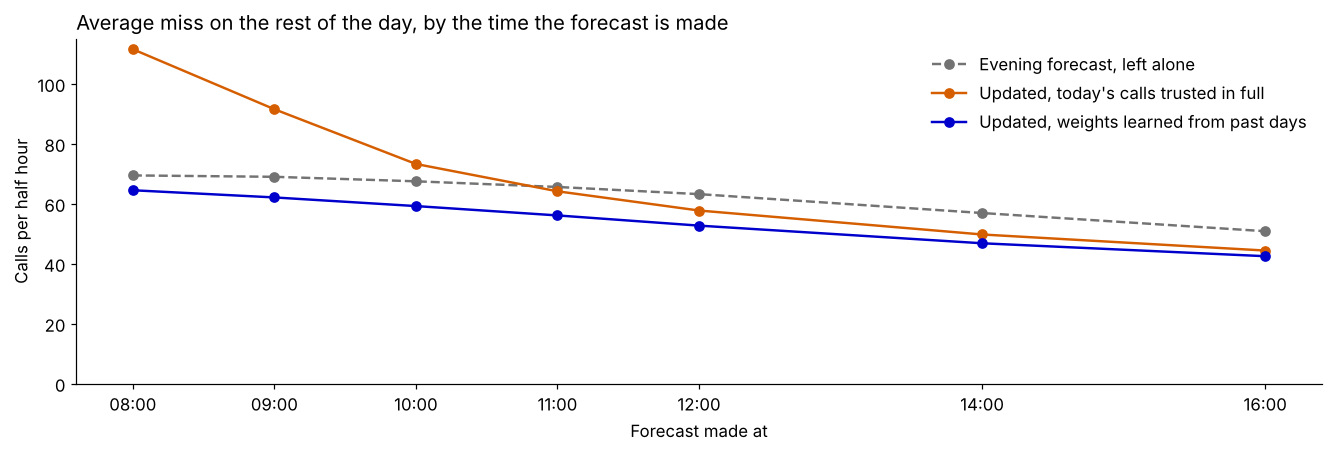

,Left alone,Trusted in full,Learned weights
Forecast made at,,,
08:00,69.4,111.5,64.5
09:00,68.9,91.5,62.1
10:00,67.4,73.2,59.2
11:00,65.6,64.1,56.1
12:00,63.2,57.7,52.7
14:00,56.9,49.7,46.8
16:00,50.8,44.4,42.5


,Weight on yesterday,Weight on today so far
Forecast made at,,
08:00,0.38,0.21
09:00,0.32,0.30
10:00,0.22,0.42
11:00,0.17,0.50
12:00,0.14,0.57
14:00,0.03,0.66
16:00,-0.06,0.73


In [7]:
class Updated(SameWeekdays):
    "SameWeekdays, with the whole day moved up or down by how yesterday went and how today is going."

    def __init__(self, weeks=4, trust="learned"):
        super().__init__(weeks)
        self.trust = trust

    def fit(self, history):
        super().fit(history)
        calls = history["calls"].to_numpy(float)
        known = len(calls) % SLOTS                        # half hours of today already in
        table = calls[: len(calls) - known].reshape(-1, SLOTS)
        weekday = history.index[: len(calls) - known : SLOTS].day_of_week.to_numpy()
        usual = np.full(table.shape, np.nan)              # what SameWeekdays would have said for each past day
        for day in range(len(table)):
            before = table[:day][weekday[:day] == weekday[day]][-self.weeks:]
            if len(before) == self.weeks:
                usual[day] = before.mean(axis=0)

        # Known at forecast time: yesterday's surprise, and today's so far once the day has started.
        past, now = [above(table, usual)[:-1]], [above(table[-1], usual[-1])]
        if known:
            today = self.usual_[history.index[-1].day_of_week]
            past.append(above(table[1:, :known], usual[1:, :known]))
            now.append(above(calls[-known:], today[:known]))
        if self.trust == "full":
            self.weights_ = np.array([0.0, 1.0])[: len(now)]
        else:                                             # least squares: what followed such surprises on past days?
            followed = above(table[1:, known:], usual[1:, known:])
            ready = ~np.isnan(np.column_stack(past + [followed])).any(axis=1)
            self.weights_ = np.linalg.lstsq(np.column_stack(past)[ready], followed[ready], rcond=None)[0]
        self.lift_ = 1 + float(np.dot(self.weights_, now))
        return self

    def predict(self, dates):
        return super().predict(dates) * self.lift_


evening_run = run_all(Updated(), evening)
evening_forecast = np.array([entry.forecast.point[:, 0] for entry in evening_run.cases])
print(f"The evening before, average of the last 4 same weekdays: {miss[best].mean():.1f}")
print(f"The evening before, with yesterday's surprise:           {metric(evening_run).mean():.1f}")

clocks = {"08:00": 2, "09:00": 4, "10:00": 6, "11:00": 8, "12:00": 10, "14:00": 14, "16:00": 18}
kept, by_clock, weights = {}, {}, {}
for clock, known in clocks.items():
    cases = cases_at(known)
    kept[clock] = {"Trusted in full": run_all(Updated(trust="full"), cases), "Learned weights": run_all(Updated(), cases)}
    by_clock[clock] = {"Left alone": np.abs(evening_forecast[:, known:] - came[:, known:]).mean(),
                       **{name: metric(run).mean() for name, run in kept[clock].items()}}
    weights[clock] = Updated().fit(calls.iloc[: SLOTS * (len(days) - 1) + known]).weights_   # as learned for the last day
by_clock = pd.DataFrame(by_clock).T
weights = pd.DataFrame(weights, index=["Weight on yesterday", "Weight on today so far"]).T

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
styles = {"Left alone": ("0.45", "--"), "Trusted in full": ("#D55E00", "-"), "Learned weights": ("#0000CC", "-")}
labels = {"Left alone": "Evening forecast, left alone", "Trusted in full": "Updated, today's calls trusted in full",
          "Learned weights": "Updated, weights learned from past days"}
hour = [7 + known / 2 for known in clocks.values()]
for name, (color, line) in styles.items():
    ax.plot(hour, by_clock[name], color=color, linestyle=line, marker="o", linewidth=1.6, label=labels[name])
ax.set_xticks(hour, list(clocks))
ax.set(title="Average miss on the rest of the day, by the time the forecast is made",
       xlabel="Forecast made at", ylabel="Calls per half hour", ylim=(0, None))
ax.legend()
plt.show()

display(by_clock.round(1).rename_axis("Forecast made at"))
display(weights.round(2).rename_axis("Forecast made at"))

gain = 100 * (1 - by_clock["Learned weights"] / by_clock["Left alone"])
assert round(metric(evening_run).mean(), 1) == 68.0
assert (by_clock["Learned weights"] < by_clock[["Left alone", "Trusted in full"]].min(axis=1)).all()
assert (by_clock["Trusted in full"] > by_clock["Left alone"]).loc[:"10:00"].all()
assert (by_clock["Trusted in full"] < by_clock["Left alone"]).loc["11:00":].all()
assert gain.round().loc[["08:00", "10:00", "12:00"]].tolist() == [7, 12, 17]
assert by_clock.round(1).loc["08:00"].tolist() == [69.4, 111.5, 64.5]
assert weights.round(2).loc["08:00"].tolist() == [0.38, 0.21] and weights.round(2).loc["10:00"].tolist() == [0.22, 0.42]
assert abs(weights.loc["14:00", "Weight on yesterday"]) < 0.05 and (weights["Weight on today so far"] < 0.8).all()

Three things to read off.

**Yesterday's surprise is worth 15%.** The evening before, moving tomorrow up or down by a part of how yesterday went takes the miss from 79.7 to 68.0. So the evening does know more than two weeks ahead, once the forecaster looks at the right thing. That forecast is the one called *left alone* in the picture and the table: the best available the evening before.

**The learned update is ahead at every hour.** At 8:00, with two half hours of calls in, it already beats the evening forecast by 7%. At 10:00 the gain is 12%, and at noon 17%.

**Trusting today in full is the worst of the three until late morning.** At 8:00 it misses by 111.5 calls where the evening forecast, left alone, misses by 69.4. An hour of calls says little about the afternoon, and five hours say a lot. The weights tell the same story. At 8:00 the update leans on yesterday more than on today. By 10:00 it leans on today twice as much, and by 14:00 yesterday no longer counts. Even then today's weight stays well below 1, and the learned update is still ahead of full trust at 16:00.

## One day

The largest surprise of the test came on Tuesday 2 September, the day after Labor Day. Here is that day as the center saw it.

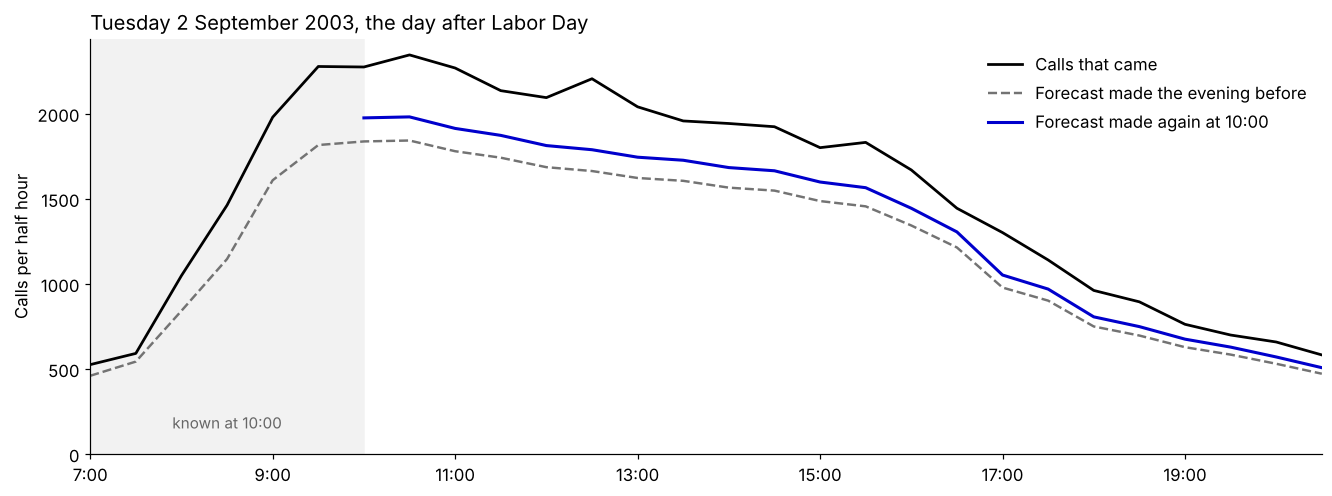

By 10:00: 7,882 calls taken, 6,413 forecast (+23%).
From 10:00 on: 34,924 calls came.
  The evening forecast had 27,921 (-20%).
  The 10:00 forecast had   30,024 (-14%).
The update closed 30% of the gap.


In [8]:
day = list(test_days).index(pd.Timestamp("2003-09-02"))
updated = kept["10:00"]["Learned weights"].cases[day].forecast.point[:, 0]
hours = 7 + np.arange(SLOTS) / 2

fig, ax = plt.subplots(figsize=(12, 4.4), layout="constrained")
ax.axvspan(7, 10, color="0.95", zorder=0)
ax.plot(hours, came[day], color="black", linewidth=1.8, label="Calls that came")
ax.plot(hours, evening_forecast[day], color="0.45", linestyle="--", linewidth=1.6, label="Forecast made the evening before")
ax.plot(hours[6:], updated, color="#0000CC", linewidth=2, label="Forecast made again at 10:00")
ax.text(8.5, 150, "known at 10:00", ha="center", color="0.4", fontsize=10)
ax.set_xticks(range(7, 22, 2), [f"{hour}:00" for hour in range(7, 22, 2)])
ax.set(title="Tuesday 2 September 2003, the day after Labor Day", ylabel="Calls per half hour",
       xlim=(7, 20.5), ylim=(0, None))
ax.legend(loc="upper right")
plt.show()

so_far, expected_so_far = came[day, :6].sum(), evening_forecast[day, :6].sum()
left, evening_left, updated_left = came[day, 6:].sum(), evening_forecast[day, 6:].sum(), updated.sum()
print(f"By 10:00: {so_far:,.0f} calls taken, {expected_so_far:,.0f} forecast ({100 * (so_far / expected_so_far - 1):+.0f}%).")
print(f"From 10:00 on: {left:,.0f} calls came.")
print(f"  The evening forecast had {evening_left:,.0f} ({100 * (evening_left / left - 1):+.0f}%).")
print(f"  The 10:00 forecast had   {updated_left:,.0f} ({100 * (updated_left / left - 1):+.0f}%).")
closed = (updated_left - evening_left) / (left - evening_left)
print(f"The update closed {100 * closed:.0f}% of the gap.")
assert evening_left < updated_left < left and round(100 * closed) == 30

The evening forecast expected an ordinary Tuesday. By 10:00 the phones had said otherwise, and the update moved the rest of the day up. It closed 30% of the gap, not all of it, because the weights are cautious. They are cautious for a reason: in the scatter above, four of the five mornings more than 20% above the forecast were followed by afternoons much closer to it. This was the fifth. A day after a holiday is also something a calendar knows in advance, and neither forecast was told.

## In agents

A miss in calls becomes a miss in people. Assume one agent answers 6 calls in half an hour; the table has no handling times, so that number is ours. A plan puts on enough agents for the forecast plus a 5% margin. Two scores of our own count what happens in agent half hours: **short** when the plan had fewer agents than the calls needed, **idle** when it had more.

Three plans for the half hours from 10:00 on, each from a newer forecast: the roster's (the last four same weekdays, which was as good two weeks ahead as the evening before), the evening's (with yesterday's surprise), and the one made again at 10:00.

In [9]:
PER_AGENT = 6                                 # calls one agent answers in half an hour: our assumption
MARGIN = 0.05                                 # agents put on beyond the forecast
FROM_TEN = SLOTS - 6                          # the 22 half hours from 10:00 on


def agents(calls):
    return np.ceil(np.asarray(calls, dtype=float) / PER_AGENT)


def miss_from_ten(observed, predicted):
    return float(np.abs(observed[-FROM_TEN:] - predicted[-FROM_TEN:]).mean())


def short(observed, predicted):
    "Agent half hours the plan was short of what the calls needed, from 10:00 on."
    need, plan = agents(observed[-FROM_TEN:]), agents(predicted[-FROM_TEN:] * (1 + MARGIN))
    return float(np.clip(need - plan, 0, None).sum())


def idle(observed, predicted):
    "Agent half hours the plan had beyond what the calls needed, from 10:00 on."
    need, plan = agents(observed[-FROM_TEN:]), agents(predicted[-FROM_TEN:] * (1 + MARGIN))
    return float(np.clip(plan - need, 0, None).sum())


ours = {"miss_from_ten": miss_from_ten, "short": short, "idle": idle}
plans = {"Roster forecast": run_all(SameWeekdays(4), evening, ours),
         "Evening forecast": run_all(Updated(), evening, ours),
         "10:00 forecast": run_all(Updated(), cases_at(6), ours)}
needed = agents(came[:, 6:]).sum(axis=1).mean()
staffing = pd.DataFrame({"Miss (calls)": {name: metric(run, "miss_from_ten").mean() for name, run in plans.items()},
                         "Agents short": {name: metric(run, "short").mean() for name, run in plans.items()},
                         "Agents idle": {name: metric(run, "idle").mean() for name, run in plans.items()}})
display(staffing.round(1).rename_axis("From 10:00 on"))
print("Short and idle are in agent half hours a day.")
print(f"Agent half hours needed from 10:00 on, on an average day: {needed:,.0f}")

print("What forecasting again at 10:00 changes, day by day, with a 95% interval:")
high = {}
for earlier in ("Roster forecast", "Evening forecast"):
    for name, label in (("miss_from_ten", "miss, calls"), ("short", "agents short")):
        gap = paired_t_interval(metric(plans["10:00 forecast"], name) - metric(plans[earlier], name))
        high[earlier, name] = gap["ci95"][1]
        print(f"  against the {earlier.lower():17s}{label:13s}{gap['mean']:+6.1f}  ({gap['ci95'][0]:+.1f} to {gap['ci95'][1]:+.1f})")

assert staffing.round(1)["Agents short"].tolist() == [71.6, 53.6, 41.5]
assert staffing.round(1)["Agents idle"].tolist() == [287.7, 277.8, 259.9]
assert staffing.round(1)["Miss (calls)"].tolist() == [78.2, 67.4, 59.2]
assert [value < 0 for value in high.values()] == [True, True, True, False] and round(needed, -2) == 4400
fewer = 100 * (1 - staffing.loc["10:00 forecast"] / staffing.loc["Roster forecast"])
assert round(fewer["Agents short"]) == 42 and round(fewer["Agents idle"]) == 10

,Miss (calls),Agents short,Agents idle
From 10:00 on,,,
Roster forecast,78.2,71.6,287.7
Evening forecast,67.4,53.6,277.8
10:00 forecast,59.2,41.5,259.9


Short and idle are in agent half hours a day.
Agent half hours needed from 10:00 on, on an average day: 4,402
What forecasting again at 10:00 changes, day by day, with a 95% interval:
  against the roster forecast  miss, calls   -19.0  (-25.8 to -12.3)
  against the roster forecast  agents short  -30.1  (-50.6 to -9.7)
  against the evening forecast miss, calls    -8.3  (-12.5 to -4.0)
  against the evening forecast agents short  -12.1  (-24.4 to +0.1)


Each newer forecast leaves fewer half hours short and fewer idle, at the same 5% margin. Against the roster's plan, the 10:00 plan is short by 41.5 agent half hours a day where the roster's is short by 71.6 (42% fewer), and idle by 259.9 where the roster's is idle by 287.7 (10% fewer), out of about 4,400 needed. Both of those differences have intervals clear of zero.

The last step on its own, from the evening plan to the 10:00 plan, is clear of zero in calls (8.3 fewer per half hour, interval 4.0 to 12.5). In agents it is not quite: 12.1 fewer half hours short a day, with an interval that runs from 24.4 fewer to 0.1 more. On 104 days that step is likely, not settled.

So the answer to "what is a newer forecast worth" has three parts. Waiting from two weeks ahead to the evening before is worth nothing if the forecast is an average of past weeks. It is worth 15% once the forecast looks at how yesterday went. And forecasting again at 10:00 is worth another 12%, provided the morning is weighed and not taken at face value.

## What TimeGym added

- **Cases on the center's own calendar.** An origin is a number of rows and so is a horizon. One line cut the evening cases, another the cases at seven times of day from 8:00 to 16:00, another the cases two weeks ahead. Each time the forecaster was handed what was known at that moment and nothing later, which is what makes "forecast again at 10:00" a fair test.
- **A refusal with a reason.** The built-in forecasters would not run on a calendar where a step has no fixed length, and every case said why. Counting rows on that calendar anyway is the mistake that cost 18%.
- **History with its dates.** A forecaster of your own is handed the dates of the history and the dates to forecast, so finding "the same weekday" is a lookup.
- **Metrics of our own.** The miss on the tenth day of a ten-day forecast, and agent half hours short and idle, were recorded for every case beside the built-in metrics.
- **Kept runs.** Every forecast and every answer stayed available afterwards: for the surprises, for the picture of 2 September, and for the day-by-day intervals.

## Change one thing

- Tell the forecaster about the day after a holiday. It is handed `dates`, so it can check whether the working day before is missing from the calendar. Does that help on 7 July, 2 September and 15 October?
- Average more weeks: `SameWeekdays(8)`. Does the update still gain as much on top of it?
- Plan the afternoon at noon: `cases_at(10)`, and count the agent half hours from 12:00 on.
- Change `MARGIN`. At which margin is the roster's plan as rarely short as the 10:00 plan at 5%, and how many more idle half hours does it cost?
- Go finer: `load("bank-calls", full=True)` has the calls of every five minutes.

**What this doesn't show.** One call center, seven months, 104 test days. The staffing rule is a stand-in: a real center plans from handling times, waiting times and a service target, and this table has only the calls that were handled. One margin was tried. The forecasters are deliberately simple, and a better one may leave less for the update to add. Days next to each other are not independent, which makes the intervals somewhat too narrow.

**Related:** [Custom model](../tutorials/02_custom_model.ipynb) for the `fit` and `predict` a forecaster of your own needs, [Your own metrics](../docs/api/diagnostics.md#your-own-metrics) in the reference, [Electricity demand](electricity-demand.ipynb) for another calendar that matters, and [Weekly shop sales](store-sales.ipynb) for a forecast turned into an order. More examples are on the [examples page](../docs/examples.md).